# Exploratary Data Analysis

- Problem Statement: The goal of this project is to train a CNN model to predict what the Pancam image contains based on the image passed into it to aid researchers in picking what images they want to look at for example they want to see soil data the model would then pick only the images that contain soil

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.preprocessing import MultiLabelBinarizer
import cv2


## Data

In [2]:
# Read in text files with the filenames and labels 
def read_txt_files(path):

    rows = []

    with open(path, encoding='UTF-8') as f:
        
        for line in f:

            line = line.strip()

            filename = line.split(",")[0]

            labels = line.split(",")[1:]

            rows.append({'filename':filename, 'labels':labels})

        data = pd.DataFrame(rows)

        return data

test_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/test-set-v1.1.0.txt')

train_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/train-set-v1.1.0.txt')

val_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/val-set-v1.1.0.txt')


In [3]:
# We have in 55986 train data image note that this includes the augmented data aswell
print('Train Data Shape: ', train_data.shape)

# 742 Test data image
print('Test Data Shape: ', test_data.shape)

# 14136 val data images
print('Val Data Shape', val_data.shape)


Train Data Shape:  (55986, 2)
Test Data Shape:  (742, 2)
Val Data Shape (14136, 2)


In [4]:
# Around 30 rows in the train data are not in the images so will drop these rows doesnt seem to be the same in val and test data so will leave as is there
image_dir = Path('rover_image_classification/mer-labeled-data-set-v1.1.0/images')

folder_files = []

for f in image_dir.iterdir():

    folder_files.append(f.name)

folder_files = pd.DataFrame(folder_files,columns=['filename'])

# No missing files in these datasets
print('Missing Files in Val Data: ', len(val_data[~val_data['filename'].isin(folder_files['filename'])]))
print('Missing Files in Test Data: ', len(test_data[~test_data['filename'].isin(folder_files['filename'])]))

# 30 missing files in Train
print('Missing Files in Train Data Data: ', len(train_data[~train_data['filename'].isin(folder_files['filename'])]))

drop_train_data = train_data[~train_data['filename'].isin(folder_files['filename'])].index

train_data.drop(drop_train_data,inplace=True)

Missing Files in Val Data:  0
Missing Files in Test Data:  0
Missing Files in Train Data Data:  30


In [ ]:
# Filtering the data to only contain the original images of the dataset
orig_train_data = train_data[train_data['filename'].str.endswith('img.jpg')].copy()
orig_test_data = test_data[test_data['filename'].str.endswith('img.jpg')].copy()
orig_val_data = val_data[val_data['filename'].str.endswith('img.jpg')].copy()

orig_train_data['split'] = 'train'
orig_test_data['split'] = 'test'
orig_val_data['split'] = 'val'

# Getting the properties of each image
def get_properties(images):

    with Image.open(image_dir/images) as im:

        image_props = {'width':im.width, 'height':im.height, 'mode':im.mode}

        array = np.asarray(im.convert('L'), dtype='float32')

        image_props['mean_intensity'] = array.mean()
        image_props['std_intensity'] = array.std()
        image_props['min_intensity'] = array.min()
        image_props['max_intensity'] = array.max()
        hist = np.bincount(array.astype(np.uint8).ravel(), minlength=256) / array.size
        hist = hist[hist >0]
        image_props['entropy'] = -(hist * np.log2(hist)).sum()
        image_props['sharpness'] = cv2.Laplacian(array, cv2.CV_32F).var()
        image_props['pct_black'] = (array <= 2).mean() * 100
        image_props['pct_white'] = (array >= 253).mean() * 100
        image_props['noise'] = (array - cv2.GaussianBlur(array, (5,5), 0)).std()

    return pd.Series(image_props)


orig_train_data_properties = orig_train_data['filename'].apply(get_properties)
orig_test_data_properties = orig_test_data['filename'].apply(get_properties)
orig_val_data_properties = orig_val_data['filename'].apply(get_properties)

orig_train_data = orig_train_data.join(orig_train_data_properties)
orig_test_data = orig_test_data.join(orig_test_data_properties)
orig_val_data = orig_val_data.join(orig_val_data_properties)

# Concatenating all data into one df to perform analysis on all data
data = pd.concat([orig_train_data, orig_val_data, orig_test_data], ignore_index=True)

In [37]:
data.to_parquet('im_stats.parquet', index=False)

In [38]:
data['labels'].explode()

0                    Rover Deck
0                 Dunes/Ripples
0                          Soil
0                     Spherules
0                Nearby Surface
                 ...           
3002                     Clasts
3002              Dunes/Ripples
3002     Rock (Linear Features)
3002                       Soil
3002             Nearby Surface
Name: labels, Length: 15711, dtype: object

In [39]:
data = pd.read_parquet('im_stats.parquet')

In [40]:
data['split'].value_counts()
# Taking only the original iamges we have, 1805 train images, 742 test and 456 val 

split
train    1805
test      742
val       456
Name: count, dtype: int64

In [73]:
mlb = MultiLabelBinarizer()
y = pd.DataFrame(mlb.fit_transform(data['labels']), columns=mlb.classes_, index=data['filename']).reset_index()

### File Quality

In [42]:
data.isnull().sum()
# No null values 

filename          0
labels            0
split             0
width             0
height            0
mode              0
mean_intensity    0
std_intensity     0
min_intensity     0
max_intensity     0
entropy           0
sharpness         0
pct_black         0
pct_white         0
noise             0
dtype: int64

In [43]:
data['filename'].duplicated().sum()
# No duplicates

np.int64(0)

In [44]:
aug_val = val_data[~val_data['filename'].str.endswith('img.jpg')]
aug_test = test_data[~test_data['filename'].str.endswith('img.jpg')]
aug_train = train_data[~train_data['filename'].str.endswith('img.jpg')]

print('No. of Augmented val images: ', len(aug_val))
print('No. of Augmented test images: ', len(aug_test))
print('No. of Augmented train images: ', len(aug_train))

# No augmented test images
# 1368 augmented val images
# 54151 augmented train images

No. of Augmented val images:  13680
No. of Augmented test images:  0
No. of Augmented train images:  54151


## Image Statistics

In [45]:
data.describe()

,width,height,mean_intensity,std_intensity,min_intensity,max_intensity,entropy,sharpness,pct_black,pct_white,noise
count,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000,3003.000000
mean,980.864469,980.864469,101.654762,22.951952,0.113220,254.648346,6.013086,219.595764,0.304251,0.023163,4.547123
std,142.237319,142.237319,26.222240,8.919688,0.635793,1.414527,0.609889,115.691368,3.987054,0.611217,1.115130
min,512.000000,512.000000,0.110140,3.204611,0.000000,229.000000,0.191933,0.926234,0.000000,0.000000,0.324199
25%,1024.000000,1024.000000,87.023643,16.782572,0.000000,255.000000,5.623418,162.517639,0.002193,0.001144,3.971756
50%,1024.000000,1024.000000,103.739998,21.635057,0.000000,255.000000,6.062490,203.064438,0.005913,0.005722,4.461340
75%,1024.000000,1024.000000,117.379551,27.225885,0.000000,255.000000,6.428798,251.520882,0.010014,0.014305,5.046262
max,1024.000000,1024.000000,192.703888,82.114426,13.000000,255.000000,7.681845,1819.955078,99.288273,33.431339,11.903818


In [46]:
data[['width', 'height']].value_counts()
# 2750 1024x1024 images and 253 512x512 images

width  height
1024   1024      2750
512    512        253
Name: count, dtype: int64

In [47]:
data['mode'].value_counts()
# All grayscale images

mode
L    3003
Name: count, dtype: int64

In [48]:
data.columns

Index(['filename', 'labels', 'split', 'width', 'height', 'mode',
       'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity',
       'entropy', 'sharpness', 'pct_black', 'pct_white', 'noise'],
      dtype='object')

### Mean Intensity

In [49]:
data['mean_intensity'].describe()

count    3003.000000
mean      101.654762
std        26.222240
min         0.110140
25%        87.023643
50%       103.739998
75%       117.379551
max       192.703888
Name: mean_intensity, dtype: float64

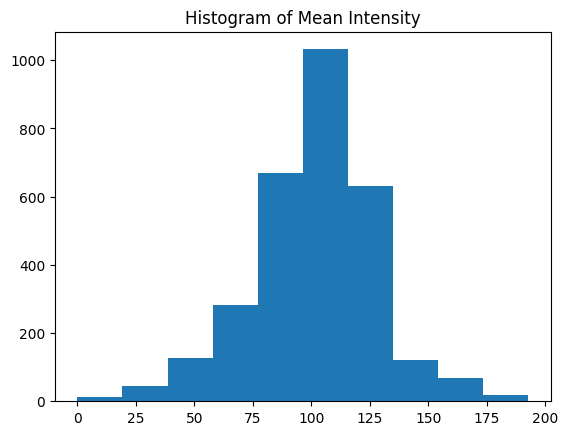

In [50]:
plt.hist(data['mean_intensity'])
plt.title('Histogram of Mean Intensity')
plt.show()
# Looks normally distributed

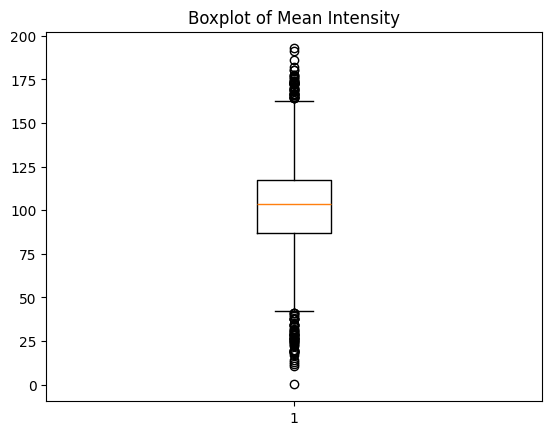

In [51]:
plt.boxplot(data['mean_intensity'])
plt.title('Boxplot of Mean Intensity')
plt.show()
# Some outliers here above around 170 and below around 50

### Std intensity

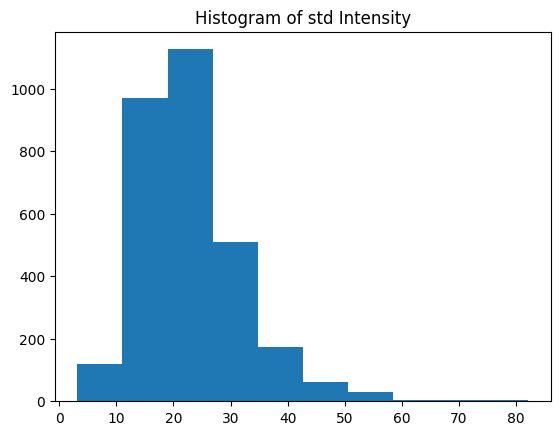

In [52]:
plt.hist(data['std_intensity'])
plt.title('Histogram of std Intensity')
plt.show()
# Looks slightly right skewed

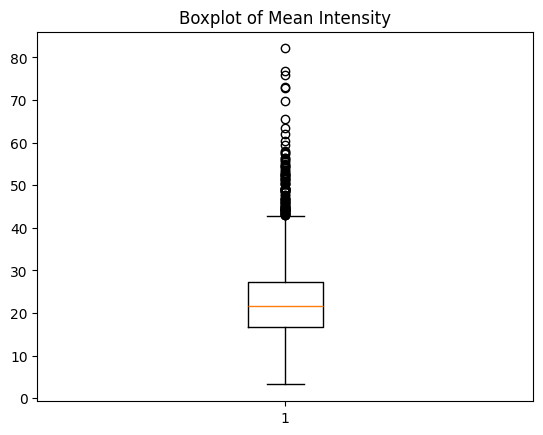

In [53]:
plt.boxplot(data['std_intensity'])
plt.title('Boxplot of Mean Intensity')
plt.show()
# Some outliers here above around 45

### Entropy

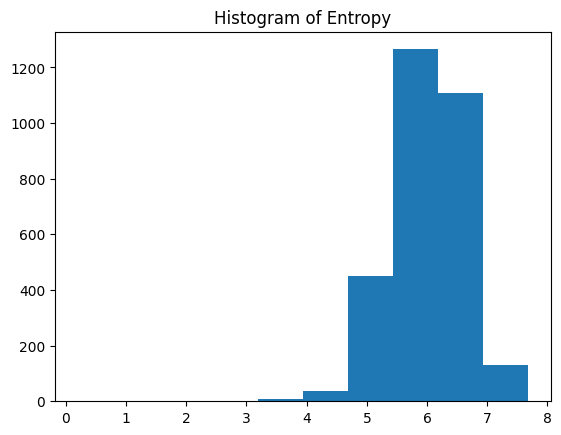

In [54]:
plt.hist(data['entropy'])
plt.title('Histogram of Entropy')
plt.show()
# Looks slightly left skewed

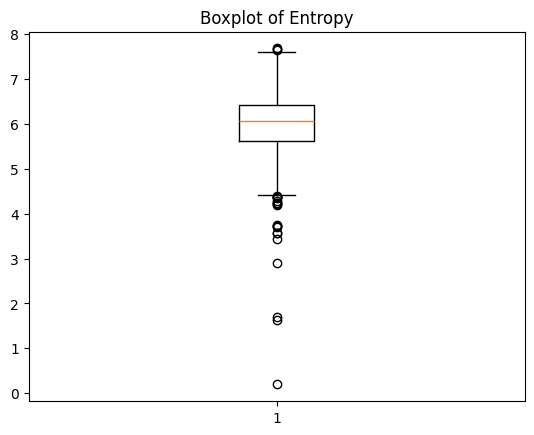

In [55]:
plt.boxplot(data['entropy'])
plt.title('Boxplot of Entropy')
plt.show()
# Some outliers below 4.5

### Sharpness

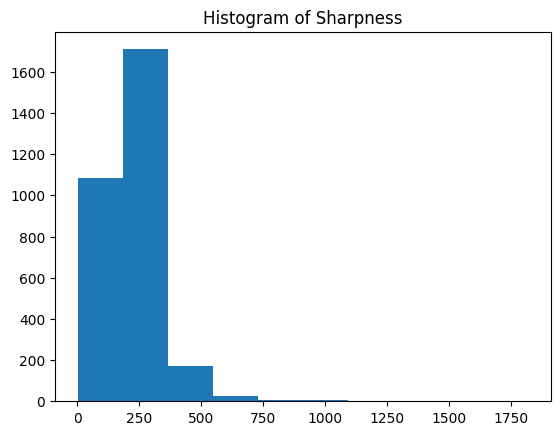

In [56]:
plt.hist(data['sharpness'])
plt.title('Histogram of Sharpness')
plt.show()
# Looks slightly right skewed

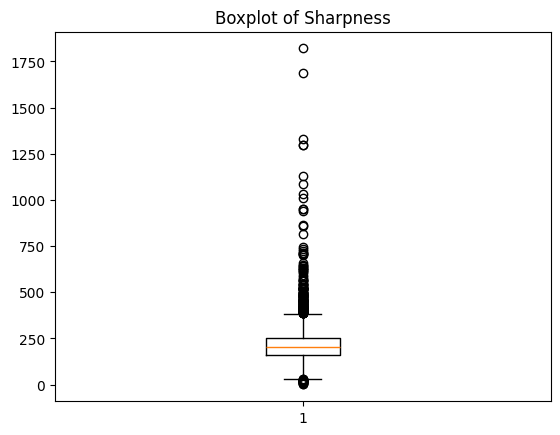

In [57]:
plt.boxplot(data['sharpness'])
plt.title('Boxplot of Sharpness')
plt.show()
# Some outliers babove 450

### pct black

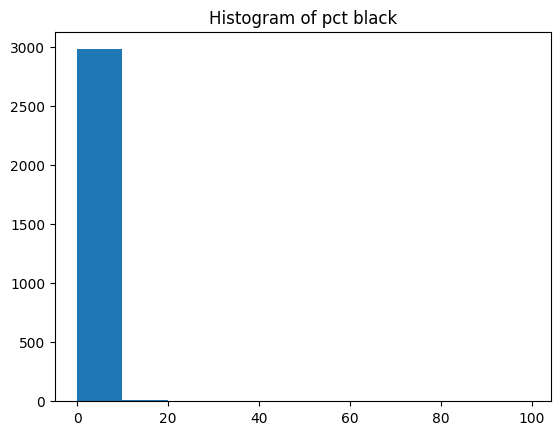

In [58]:
plt.hist(data['pct_black'])
plt.title('Histogram of pct black')
plt.show()
# Looks slightly left skewed

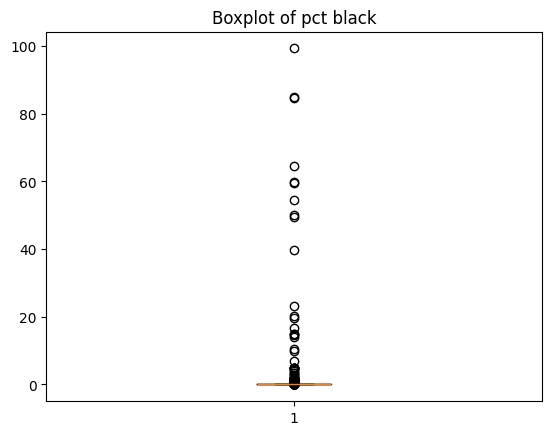

In [59]:
plt.boxplot(data['pct_black'])
plt.title('Boxplot of pct black')
plt.show()
# Some outliers above 1

### pct white

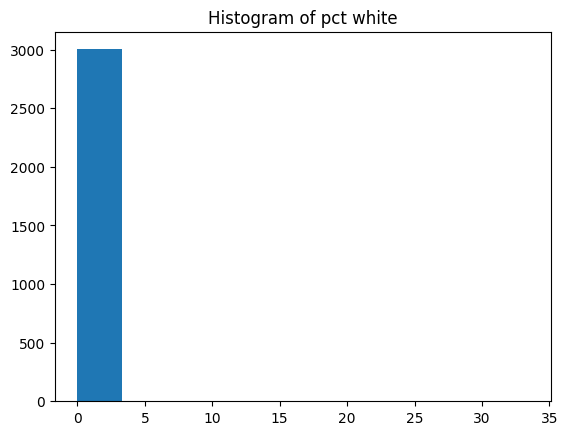

In [60]:
plt.hist(data['pct_white'])
plt.title('Histogram of pct white')
plt.show()
# Looks slightly left skewed

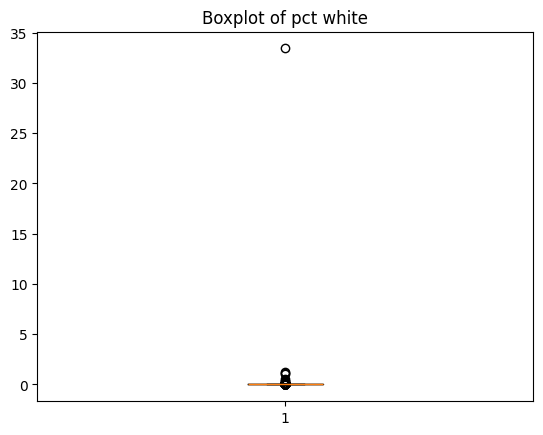

In [61]:
plt.boxplot(data['pct_white'])
plt.title('Boxplot of pct white')
plt.show()
# Some outliers above 1

### Noise

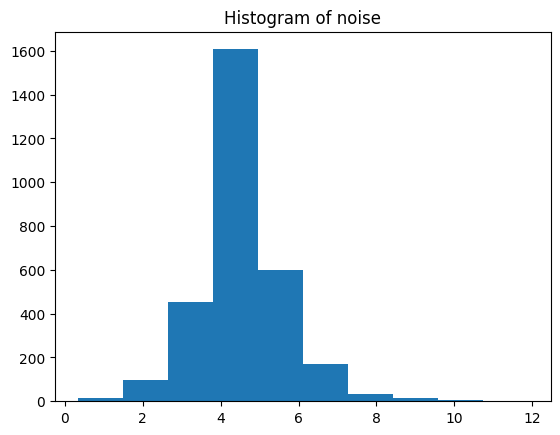

In [62]:
plt.hist(data['noise'])
plt.title('Histogram of noise')
plt.show()
# Looks normally distributed

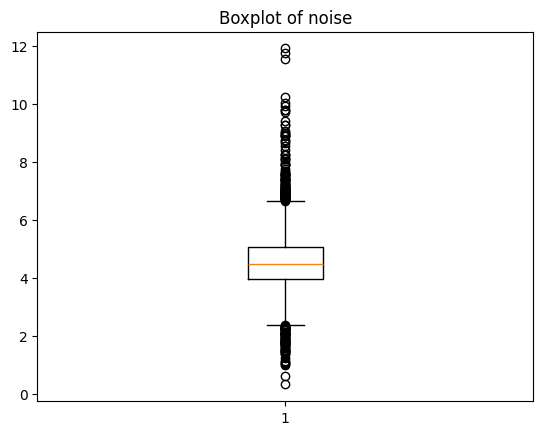

In [63]:
plt.boxplot(data['noise'])
plt.title('Boxplot of noise')
plt.show()
# Some outliers above 7 and below 3

## Images per class

In [83]:
y.columns = y.columns.str.strip()

In [85]:
a_hardware = data[y['Arm Hardware'] == 1]
artifacts = data[y['Artifacts'] == 1]
astro = data[y['Astronomy'] == 1]
bright_soil = data[y['Bright Soil'] == 1]
clasts = data[y['Clasts'] == 1]
close_rock = data[y['Close-up Rock'] == 1]
distant_vista = data[y['Distant Vista'] == 1]
dunes = data[y['Dunes/Ripples'] == 1]
float_rocks = data[y['Float Rocks'] == 1]
nearby_surface = data[y['Nearby Surface'] == 1]
o_hardware = data[y['Other Hardware'] == 1]
cal_target = data[y['Pancam Calibration Target'] == 1]
rat_brushed = data[y['RAT Brushed Target'] == 1]
rat_hole = data[y['RAT Hole'] == 1]
rock_linear = data[y['Rock (Linear Features)'] == 1]
rock_round = data[y['Rock (Round Features)'] == 1]
rock_outcrops = data[y['Rock Outcrops'] == 1]
rocks_misc = data[y['Rocks (misc)'] == 1]
rover_deck = data[y['Rover Deck'] == 1]
rover_parts = data[y['Rover Parts'] == 1]
rover_tracks = data[y['Rover Tracks'] == 1]
sky = data[y['Sky'] == 1]
soil = data[y['Soil'] == 1]
soil_trench = data[y['Soil Trench'] == 1]
spherules = data[y['Spherules'] == 1]

In [90]:
def show_label_image(var):

    img = Image.open(image_dir/var['filename'].iloc[0])

    plt.imshow(img, cmap='gray')

### Arm Hardware

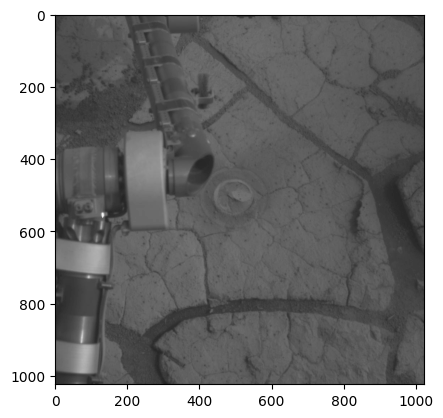

In [91]:
show_label_image(a_hardware)

### Artifacts

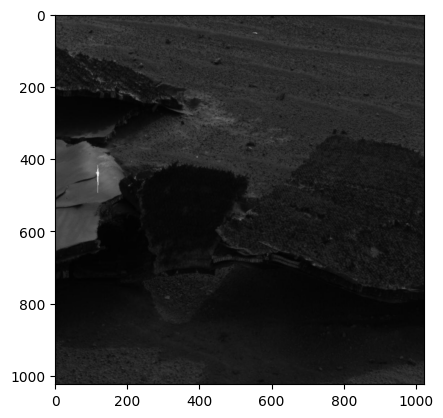

In [92]:
show_label_image(artifacts)

### Astronomy

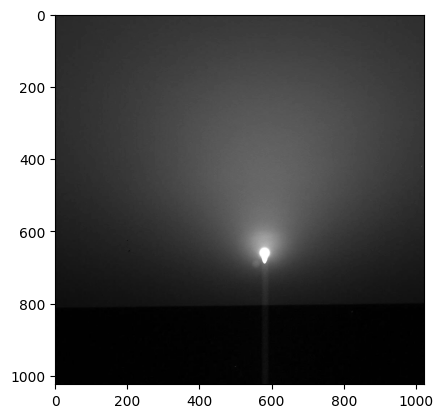

In [93]:
show_label_image(astro)

### Bright Soil

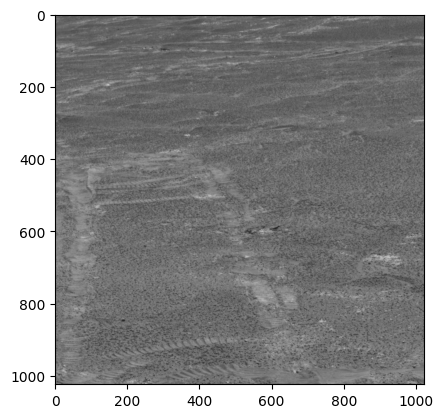

In [94]:
show_label_image(bright_soil)


### Clasts

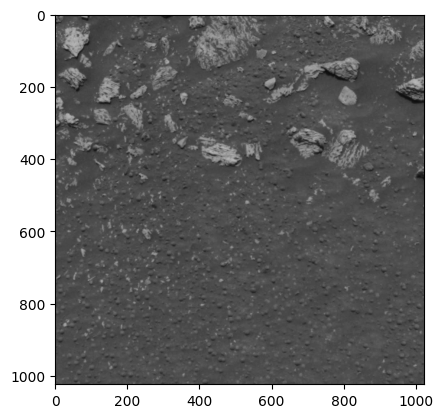

In [95]:
show_label_image(clasts)


### Close Rock

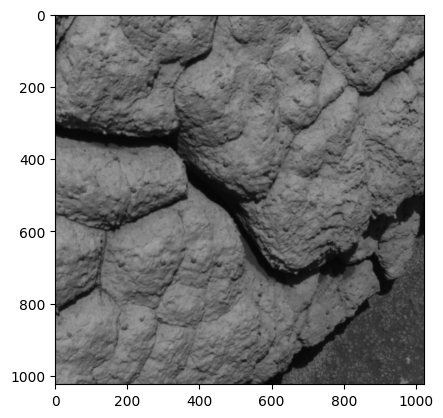

In [96]:
show_label_image(close_rock)


### Distant Vista

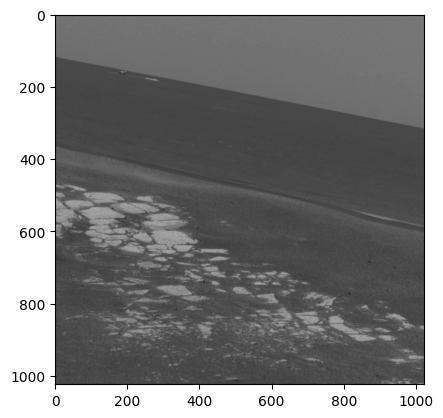

In [98]:
show_label_image(distant_vista)


### Dunes

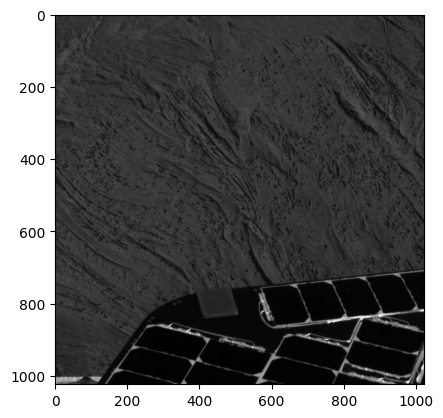

In [99]:
show_label_image(dunes)


### Float Rock

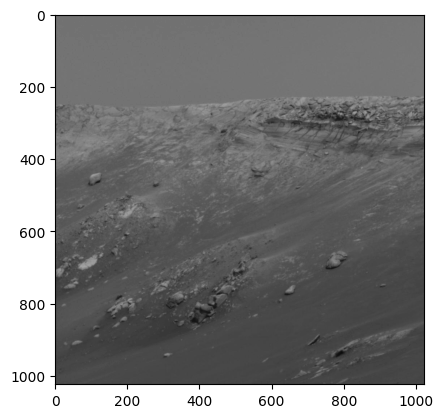

In [100]:
show_label_image(float_rocks)


### Nearby Surface

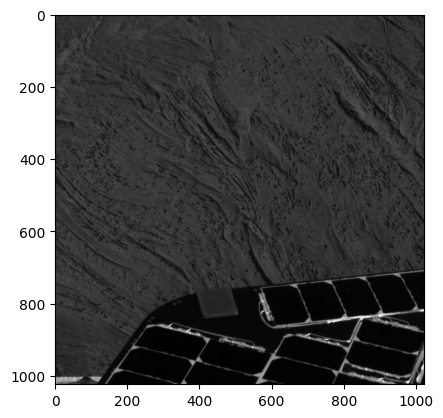

In [101]:
show_label_image(nearby_surface)


### Other Hardware

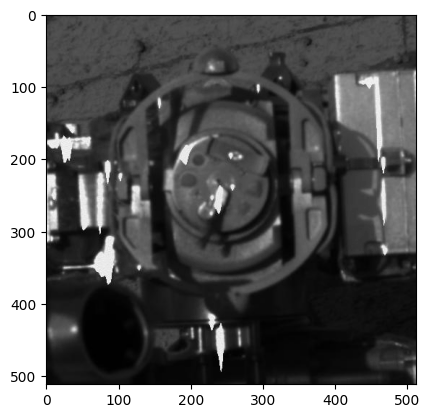

In [102]:
show_label_image(o_hardware)


### Pancam Calibration Target

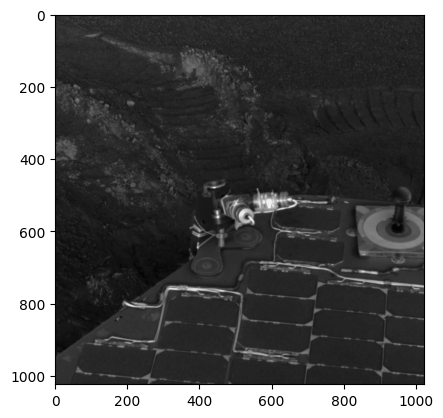

In [103]:
show_label_image(cal_target)


### Rat Brushed Target

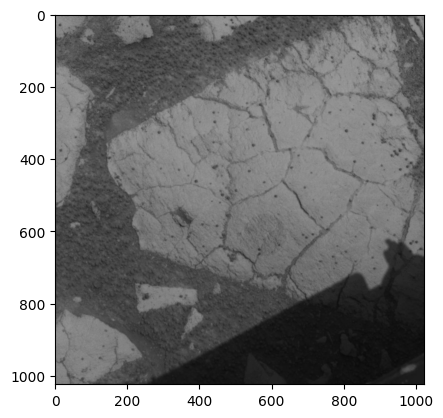

In [104]:
show_label_image(rat_brushed)


### RAT Hole

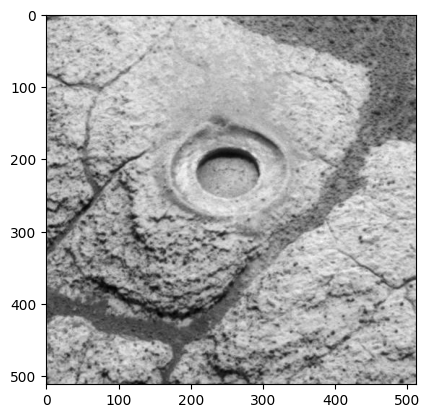

In [105]:
show_label_image(rat_hole)


### Rock Linear Features

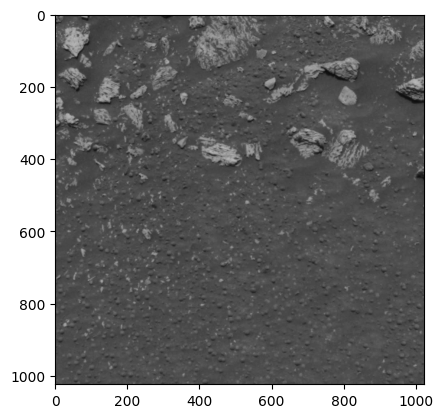

In [106]:
show_label_image(rock_linear)


### Rock Round Features

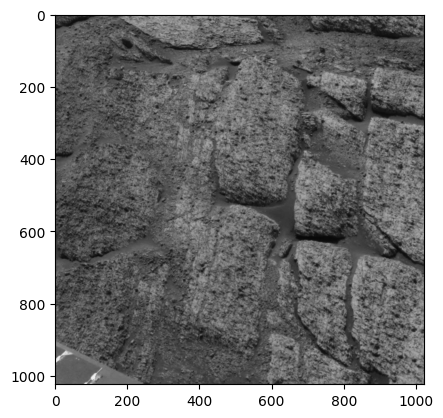

In [107]:
show_label_image(rock_round)


### Rock Outcrops 

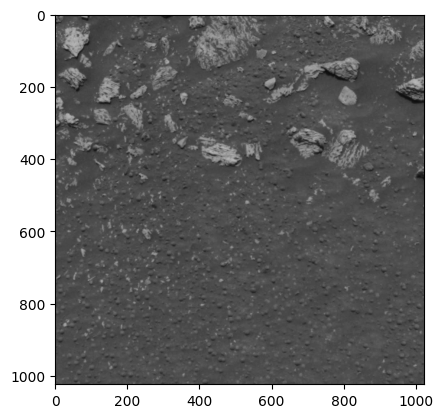

In [108]:
show_label_image(rock_outcrops)


### Rocks Miscelannous

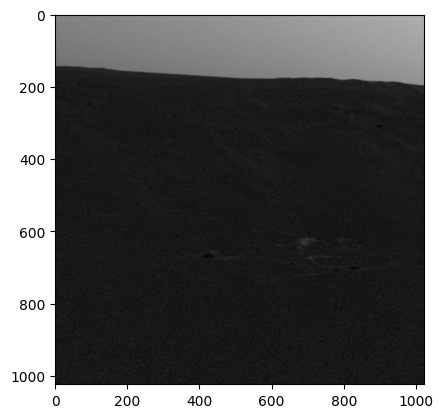

In [109]:
show_label_image(rocks_misc)


### Rover Deck 

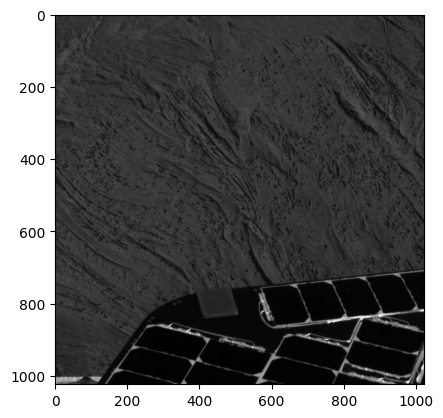

In [110]:
show_label_image(rover_deck)


### Rover Parts

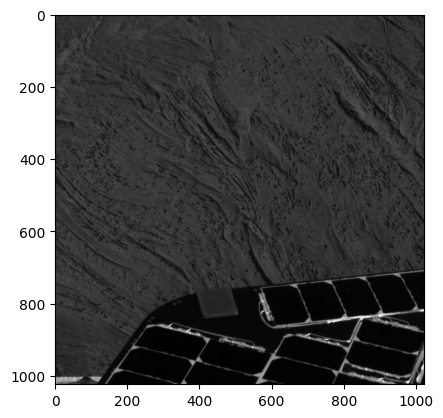

In [111]:
show_label_image(rover_parts)


### Rover Tracks

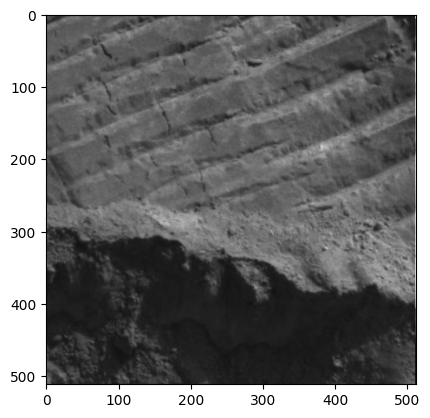

In [112]:
show_label_image(rover_tracks)


### Sky

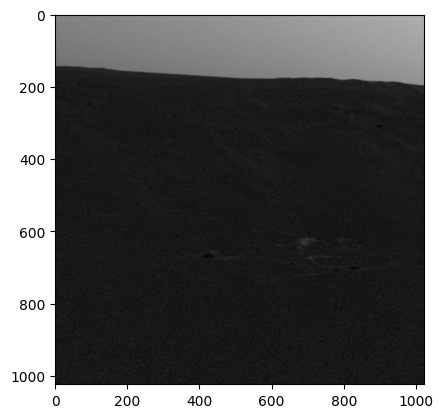

In [113]:
show_label_image(sky)


### Soil

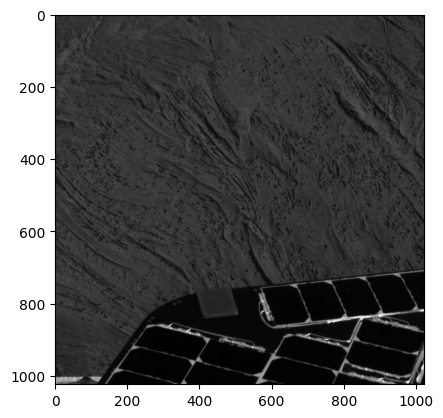

In [114]:
show_label_image(soil)


### Soil Trench

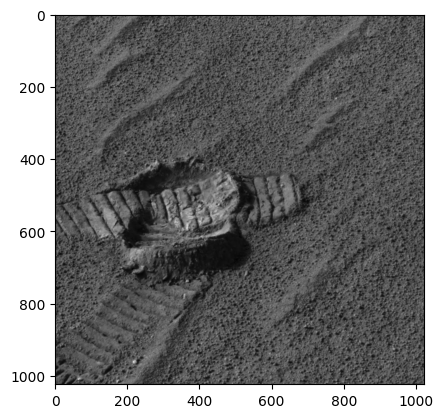

In [115]:
show_label_image(soil_trench)


### Spherules

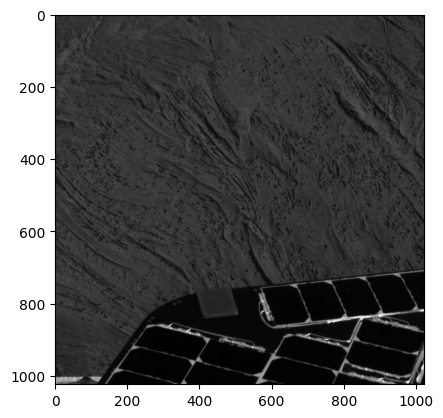

In [116]:
show_label_image(spherules)